# Resultados de clasificación de texto

En este capítulo comparamos los ocho modelos en el conjunto de test (373 currículos), evaluado una sola vez con la configuración elegida en validación. Cada modelo se entrenó con 5 semillas. Reportamos la media ± DE entre semillas y, para la predicción por voto de las 5 semillas, el IC 95 % *bootstrap* sobre documentos. Las pruebas siguen el plan pre-registrado: McNemar exacto en test, *t* de Nadeau–Bengio sobre 5 pliegues idénticos para todos los modelos y corrección de Holm. Los resultados los genera `python scripts/analysis.py nlp`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, MUTED, ci, exists, need, style

style()
pd.set_option("display.precision", 3)
S = need("analysis/nlp_stats/stats.pkl")
L = S["labels"]
COL = {m: CAT[i] for i, m in enumerate(["tfidf_lr", "nbsvm", "tfidf_xgb", "fasttext", "cnn1d", "bilstm", "distilbert", "majority"])}

## Tabla principal

In [2]:
T = S["results"].copy()
eff = need("analysis/nlp_efficiency/efficiency.pkl") if exists("analysis/nlp_efficiency/efficiency.pkl") else None
lat = eff[eff.device == "CPU"].set_index("model").lat_p50_ms if eff is not None else pd.Series(dtype=float)
tab = pd.DataFrame({
    "modelo": T.index.map(L),
    "F1 macro (media ± DE)": [f"{a:.3f} ± {b:.3f}" for a, b in zip(T.f1_macro, T.f1_macro_sd)],
    "F1 macro, voto [IC 95 %]": [ci(a, b, c) for a, b, c in zip(T.f1_vote, T.f1_vote_lo, T.f1_vote_hi)],
    "exactitud": T.accuracy, "precisión macro": T.precision_macro, "recall macro": T.recall_macro, "MCC": T.mcc,
    "ROC-AUC": T.roc_auc, "PR-AUC": T.pr_auc, "ECE": T.ece, "log-loss": T.log_loss, "Brier": T.brier,
    "latencia CPU p50 (ms)": T.index.map(lambda m: lat.get(m, np.nan)),
    "entrenamiento (s)": T.seconds_train})
tab.style.hide(axis="index").format(precision=3, na_rep="—")

modelo,F1 macro (media ± DE),"F1 macro, voto [IC 95 %]",exactitud,precisión macro,recall macro,MCC,ROC-AUC,PR-AUC,ECE,log-loss,Brier,latencia CPU p50 (ms),entrenamiento (s)
DistilBERT,0.774 ± 0.012,"0.782 [0.746, 0.809]",0.841,0.774,0.786,0.835,0.974,0.850,0.088,0.674,0.231,257.318,141.827
CNN-1D,0.766 ± 0.013,"0.779 [0.734, 0.814]",0.822,0.791,0.773,0.814,0.979,0.842,0.043,0.688,0.257,11.560,20.772
TF-IDF + XGBoost,0.730 ± 0.008,"0.742 [0.692, 0.779]",0.775,0.748,0.735,0.766,0.963,0.771,0.064,0.924,0.355,6.885,217.933
NB-SVM,0.704 ± 0.000,"0.704 [0.651, 0.744]",0.756,0.747,0.711,0.746,0.964,0.779,0.057,0.912,0.352,2.740,11.749
BiLSTM,0.700 ± 0.018,"0.720 [0.675, 0.755]",0.762,0.727,0.709,0.752,0.961,0.773,0.075,0.894,0.320,159.628,199.903
TF-IDF + RL,0.660 ± 0.000,"0.660 [0.605, 0.700]",0.713,0.706,0.669,0.701,0.948,0.738,0.069,1.070,0.410,2.827,11.073
FastText,0.450 ± 0.019,"0.500 [0.446, 0.540]",0.497,0.462,0.464,0.475,0.892,0.506,0.081,1.861,0.650,1.088,49.976
Clase mayoritaria,0.004 ± 0.000,"0.004 [0.002, 0.006]",0.048,0.002,0.042,0.000,0.500,0.042,0.000,3.141,0.956,—,0.001


In [3]:
best = T.f1_macro.idxmax()
second = T.f1_macro.drop(best).idxmax()
display(Markdown(
    f"El mejor modelo por F1 macro media es **{L[best]}** ({T.f1_macro[best]:.3f} ± {T.f1_macro_sd[best]:.3f}), seguido de "
    f"**{L[second]}** ({T.f1_macro[second]:.3f} ± {T.f1_macro_sd[second]:.3f}). La clase mayoritaria obtiene "
    f"{T.f1_macro['majority']:.3f}, el piso de referencia. La DE entre semillas va de {T.f1_macro_sd.drop('majority').min():.3f} a "
    f"{T.f1_macro_sd.drop('majority').max():.3f} según el modelo."))

El mejor modelo por F1 macro media es **DistilBERT** (0.774 ± 0.012), seguido de **CNN-1D** (0.766 ± 0.013). La clase mayoritaria obtiene 0.004, el piso de referencia. La DE entre semillas va de 0.000 a 0.019 según el modelo.

Las métricas micro y ponderadas, junto con el resto de secundarias, están en `results/analysis/nlp_stats/stats.pkl` (clave `results`). En un problema con 24 clases y un desbalance de 5.45, la F1 ponderada y la exactitud se acercan entre sí y se alejan de la F1 macro cuando un modelo falla en las clases pequeñas.

## Pruebas por pares

In [4]:
P = S["pairwise"].copy()
P["A"] = P.A.map(L); P["B"] = P.B.map(L)
P["ΔF1 (A − B) [IC 95 %]"] = [ci(a, b, c) for a, b, c in zip(P.f1_diff, P.lo, P.hi)]
cols = ["A", "B", "ΔF1 (A − B) [IC 95 %]", "p_mcnemar_holm"] + (["cv_diff", "p_nb_holm", "same_folds"] if "p_nb_holm" in P else [])
P[cols].rename(columns={"p_mcnemar_holm": "McNemar (Holm)", "cv_diff": "ΔF1 en CV", "p_nb_holm": "Nadeau–Bengio (Holm)",
                        "same_folds": "mismos pliegues"}).style.hide(axis="index").format(precision=3)

A,B,ΔF1 (A − B) [IC 95 %],McNemar (Holm),ΔF1 en CV,Nadeau–Bengio (Holm),mismos pliegues
TF-IDF + RL,NB-SVM,"-0.044 [-0.079, -0.009]",0.136,-0.063,0.229,True
TF-IDF + RL,TF-IDF + XGBoost,"-0.082 [-0.127, -0.039]",0.005,-0.055,0.188,True
TF-IDF + RL,FastText,"0.161 [0.111, 0.208]",0.000,0.095,0.042,True
TF-IDF + RL,CNN-1D,"-0.118 [-0.158, -0.082]",0.000,-0.085,0.081,True
TF-IDF + RL,BiLSTM,"-0.059 [-0.115, -0.009]",0.020,-0.037,1.000,True
TF-IDF + RL,DistilBERT,"-0.121 [-0.173, -0.079]",0.000,-0.128,0.012,True
NB-SVM,TF-IDF + XGBoost,"-0.038 [-0.085, 0.007]",0.914,0.008,1.000,True
NB-SVM,FastText,"0.205 [0.154, 0.253]",0.000,0.157,0.086,True
NB-SVM,CNN-1D,"-0.074 [-0.115, -0.038]",0.002,-0.022,1.000,True
NB-SVM,BiLSTM,"-0.015 [-0.068, 0.036]",0.914,0.026,1.000,True


In [5]:
sig = P[(P.p_mcnemar_holm < 0.05)]
display(Markdown(f"De {len(P)} pares, {len(sig)} difieren con McNemar tras Holm (α = 0.05)"
                 + (f" y {int((P.p_nb_holm < 0.05).sum())} con Nadeau–Bengio." if "p_nb_holm" in P else ".")))

De 21 pares, 14 difieren con McNemar tras Holm (α = 0.05) y 5 con Nadeau–Bengio.

Friedman sobre las F1 de los 5 pliegues (7 modelos): χ² = 26.1, p = 0.000217.

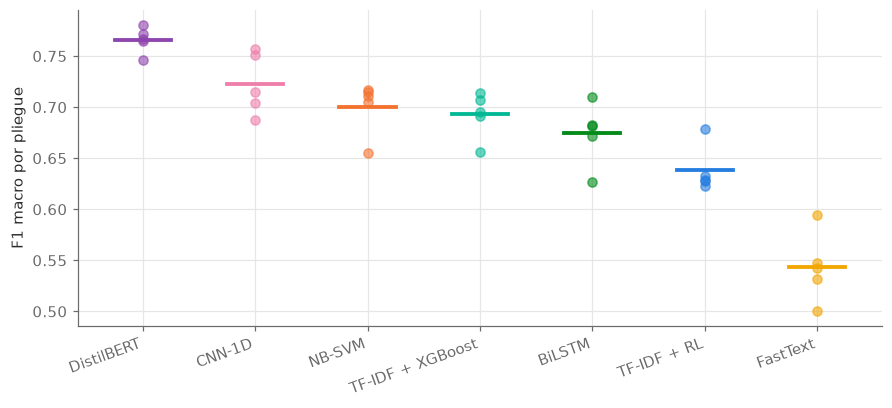

In [6]:
fr = S["friedman_cv"]
if fr:
    display(Markdown(f"Friedman sobre las F1 de los 5 pliegues ({fr['scores'].shape[1]} modelos): χ² = {fr['stat']:.1f}, p = {fr['p']:.3g}."))
    fig, ax = plt.subplots(figsize=(8, 3.6))
    sc = fr["scores"]
    for k, m in enumerate(fr["mean_ranks"].index):
        ax.plot(np.full(5, k), sc[m], "o", color=COL.get(m, MUTED), alpha=0.6)
        ax.plot([k - 0.25, k + 0.25], [sc[m].mean()] * 2, color=COL.get(m, MUTED), lw=2.5)
    ax.set_xticks(range(len(fr["mean_ranks"])), [L[m] for m in fr["mean_ranks"].index], rotation=20, ha="right")
    ax.set(ylabel="F1 macro por pliegue")
    plt.show()

## H4: DistilBERT frente a TF-IDF + XGBoost

In [7]:
h4 = S.get("h4", {})
if h4:
    display(Markdown(
        f"Diferencia de F1 macro (DistilBERT − TF-IDF + XGBoost) por voto de semillas: {ci(h4['diff_bert_minus_xgb'], h4['lo'], h4['hi'])}. "
        f"McNemar con Holm: p = {h4['p_mcnemar_holm']:.3g}; " + (f"Nadeau–Bengio con Holm: p = {h4['p_nb_holm']:.3g}. " if np.isfinite(h4['p_nb_holm']) else "Nadeau–Bengio: sin validación cruzada de DistilBERT, no calculado. ") +
        f"**H4 {'se refuta' if h4['refuted'] else 'no se refuta'}**: la diferencia {'es' if h4['refuted'] else 'no es'} "
        f"significativa tras la corrección. "
        + ("El IC cae entero dentro de [−δ, δ] = [−0.02, 0.02], así que además podemos afirmar equivalencia práctica."
           if h4["equivalent"] else "El IC no cae entero dentro de [−δ, δ] = [−0.02, 0.02]: no podemos afirmar equivalencia práctica.")))
    if h4["refuted"] and h4["lo"] <= 0 <= h4["hi"]:
        display(Markdown(
            "El veredicto sigue el criterio pre-registrado (McNemar o Nadeau–Bengio con p de Holm < 0.05), pero el IC *bootstrap* de la "
            "diferencia de F1 macro incluye el 0. Las dos cosas son compatibles porque miden cantidades distintas: McNemar compara los "
            "aciertos documento a documento, es decir, la exactitud, y Nadeau–Bengio usa las F1 de los 5 pliegues de validación cruzada; "
            "el IC de la F1 macro en test pesa igual las 24 clases, y en las clases pequeñas unos pocos documentos mueven mucho la F1. "
            "La diferencia en aciertos es significativa; la diferencia en F1 macro de test es positiva pero su IC no excluye el 0."))
else:
    display(Markdown("Falta alguno de los dos modelos; H4 queda sin contrastar."))

Diferencia de F1 macro (DistilBERT − TF-IDF + XGBoost) por voto de semillas: 0.039 [-0.002, 0.086]. McNemar con Holm: p = 0.02; Nadeau–Bengio con Holm: p = 0.0917. **H4 se refuta**: la diferencia es significativa tras la corrección. El IC no cae entero dentro de [−δ, δ] = [−0.02, 0.02]: no podemos afirmar equivalencia práctica.

El veredicto sigue el criterio pre-registrado (McNemar o Nadeau–Bengio con p de Holm < 0.05), pero el IC *bootstrap* de la diferencia de F1 macro incluye el 0. Las dos cosas son compatibles porque miden cantidades distintas: McNemar compara los aciertos documento a documento, es decir, la exactitud, y Nadeau–Bengio usa las F1 de los 5 pliegues de validación cruzada; el IC de la F1 macro en test pesa igual las 24 clases, y en las clases pequeñas unos pocos documentos mueven mucho la F1. La diferencia en aciertos es significativa; la diferencia en F1 macro de test es positiva pero su IC no excluye el 0.

## F1 por clase y matriz de confusión del mejor modelo

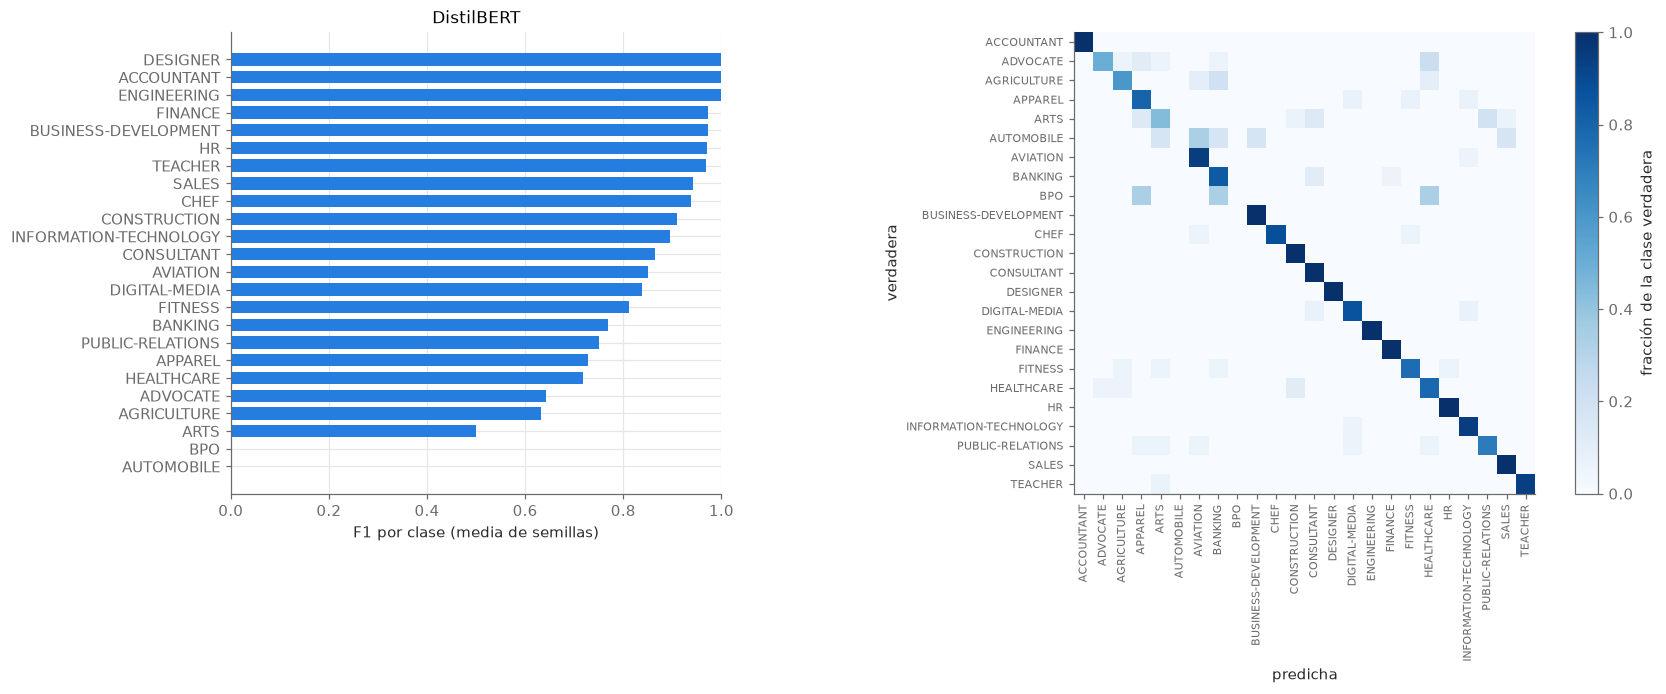

,,errores
true,pred,
ADVOCATE,HEALTHCARE,4
ARTS,PUBLIC-RELATIONS,3
ADVOCATE,APPAREL,2
ARTS,APPAREL,2
AGRICULTURE,BANKING,2
BANKING,CONSULTANT,2
AUTOMOBILE,AVIATION,2
ARTS,CONSULTANT,2


In [8]:
E = S["errors"]
cls = E["classes"]
f1c = pd.Series(E["per_class_f1"], index=cls).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw=dict(width_ratios=[1, 1.6]))
axes[0].barh(f1c.index, f1c.values, color=CAT[0], height=0.7)
axes[0].set(xlabel="F1 por clase (media de semillas)", xlim=(0, 1), title=L[E["model"]])
cm = E["confusion"]
im = axes[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(len(cls)), cls, rotation=90, fontsize=7); axes[1].set_yticks(range(len(cls)), cls, fontsize=7)
axes[1].set(xlabel="predicha", ylabel="verdadera"); axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label="fracción de la clase verdadera")
plt.show()
display(E["top_pairs"].rename("errores").to_frame().head(8))

La matriz está normalizada por fila: cada celda es la fracción de los documentos de una clase verdadera que el modelo asigna a cada clase. Los pares más confundidos son los candidatos naturales a clases afines, y la taxonomía de errores del capítulo {doc}`24_nlp_robustez_equidad` verifica si los errores se deben a la afinidad entre profesiones o a etiquetas dudosas.

## Ruido de etiquetas

Estimamos los documentos con etiqueta probablemente errónea con *confident learning* {cite:p}`northcutt2021confident` sobre las probabilidades fuera de muestra de la validación cruzada de TF-IDF + RL.

In [9]:
if exists("eda/nlp/label_noise.pkl"):
    ln = need("eda/nlp/label_noise.pkl")
    display(Markdown(f"*Confident learning* marca {ln['n_issues']} de {ln['n']} documentos de entrenamiento ∪ validación "
                     f"({100 * ln['rate']:.1f} %) como posibles errores de etiqueta."))
    iss = ln["issues"]
    display(iss.groupby(["given", "suggested"]).size().sort_values(ascending=False).head(10).rename("documentos").to_frame())
else:
    display(Markdown("El análisis de ruido de etiquetas no se ejecutó (`python scripts/eda.py noise`)."))

*Confident learning* marca 364 de 2109 documentos de entrenamiento ∪ validación (17.3 %) como posibles errores de etiqueta.

,,documentos
given,suggested,
TEACHER,ARTS,10
ARTS,TEACHER,8
ADVOCATE,HEALTHCARE,8
CONSULTANT,INFORMATION-TECHNOLOGY,8
APPAREL,SALES,8
SALES,APPAREL,7
FINANCE,ACCOUNTANT,7
ARTS,SALES,6
HEALTHCARE,ADVOCATE,6


In [10]:
from sklearn.metrics import f1_score  # noqa: E402

cvl = need("nlp/tfidf_lr/cv_standard/cv.pkl")
display(Markdown(
    "*Confident learning* marca un documento cuando la probabilidad fuera de muestra de otra clase supera el umbral propio de esa "
    f"clase. Las probabilidades vienen de TF-IDF + RL en 5 pliegues, cuya F1 macro fuera de muestra es "
    f"{f1_score(cvl['y'], cvl['oof'].argmax(1), average='macro'):.3f}: una parte de los marcados son errores del clasificador sobre "
    "perfiles ambiguos y no etiquetas equivocadas, así que la tasa es una cota superior del ruido real. Un documento marcado puede ser "
    "también un perfil mixto con dos etiquetas válidas."))

*Confident learning* marca un documento cuando la probabilidad fuera de muestra de otra clase supera el umbral propio de esa clase. Las probabilidades vienen de TF-IDF + RL en 5 pliegues, cuya F1 macro fuera de muestra es 0.643: una parte de los marcados son errores del clasificador sobre perfiles ambiguos y no etiquetas equivocadas, así que la tasa es una cota superior del ruido real. Un documento marcado puede ser también un perfil mixto con dos etiquetas válidas.

Para medir el efecto sobre las conclusiones, reentrenamos los modelos ligeros sin los documentos de entrenamiento marcados (3 semillas) y evaluamos en el mismo test sin tocar. La tabla incluye los modelos cuyo reentrenamiento terminó dentro del presupuesto.

In [11]:
ne = S.get("noise_effect", pd.DataFrame())
if len(ne):
    ne = ne.assign(modelo=ne.model.map(L))
    display(ne[["modelo", "n_removed", "f1_full", "f1_clean", "diff", "rank_full", "rank_clean"]].rename(columns={
        "n_removed": "documentos retirados", "f1_full": "F1 (entrenamiento completo)", "f1_clean": "F1 (sin marcados)",
        "diff": "diferencia", "rank_full": "puesto completo", "rank_clean": "puesto sin marcados"}).style.hide(axis="index").format(precision=3))
    same = (ne.rank_full == ne.rank_clean).all()
    display(Markdown(f"El orden de los {len(ne)} modelos reentrenados no cambia al retirar los documentos marcados." if same else
                     "El orden de los modelos cambia al retirar los documentos marcados: las diferencias entre ellos son del orden del efecto del ruido."))
else:
    display(Markdown("El reentrenamiento sin documentos marcados no terminó (`python scripts/nlp.py noise --model <modelo>`)."))

modelo,documentos retirados,F1 (entrenamiento completo),F1 (sin marcados),diferencia,puesto completo,puesto sin marcados
TF-IDF + RL,285,0.660,0.651,-0.009,3,3
NB-SVM,285,0.704,0.663,-0.042,2,2
TF-IDF + XGBoost,285,0.728,0.705,-0.022,1,1
FastText,285,0.440,0.490,0.050,4,4


El orden de los 4 modelos reentrenados no cambia al retirar los documentos marcados.